In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Superstore dataset
df = pd.read_csv("Sample - Superstore.csv", encoding="cp1252")

# Display the first five rows
df.head()


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [4]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sum())


Dataset shape: (9994, 21)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Po

In [5]:

# Convert date columns to datetime format
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], errors="coerce")

# Verify the changes
print(df[["Order Date", "Ship Date"]].dtypes)

# Display sample dates
df[["Order Date", "Ship Date"]].head()


Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


,Order Date,Ship Date
0,2016-11-08,2016-11-11
1,2016-11-08,2016-11-11
2,2016-06-12,2016-06-16
3,2015-10-11,2015-10-18
4,2015-10-11,2015-10-18


In [6]:

# Count completely duplicated rows
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)


Duplicate rows: 0


In [7]:

# Summary statistics for numerical columns
df[["Sales", "Quantity", "Discount", "Profit"]].describe().round(2)


,Sales,Quantity,Discount,Profit
count,9994.00,9994.00,9994.00,9994.00
mean,229.86,3.79,0.16,28.66
std,623.25,2.23,0.21,234.26
min,0.44,1.00,0.00,-6599.98
25%,17.28,2.00,0.00,1.73
50%,54.49,3.00,0.20,8.67
75%,209.94,5.00,0.20,29.36
max,22638.48,14.00,0.80,8399.98


In [8]:

# Calculate overall business performance

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_products = df["Product Name"].nunique()
total_customers = df["Customer ID"].nunique()
total_quantity = df["Quantity"].sum()

profit_margin = (total_profit / total_sales) * 100

print("========== BUSINESS SALES PERFORMANCE ==========")
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Unique Orders: {total_orders:,}")
print(f"Unique Products: {total_products:,}")
print(f"Unique Customers: {total_customers:,}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Overall Profit Margin: {profit_margin:.2f}%")


========== BUSINESS SALES PERFORMANCE ==========
Total Sales: $2,297,200.86
Total Profit: $286,397.02
Unique Orders: 5,009
Unique Products: 1,850
Unique Customers: 793
Total Quantity Sold: 37,873
Overall Profit Margin: 12.47%


In [9]:

# Group data by product
product_performance = (
    df.groupby("Product Name")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Units_Sold=("Quantity", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
)

# Top 10 products by sales
print("TOP 10 PRODUCTS BY SALES")
display(product_performance.head(10).round(2))

# Top 10 products by profit
print("TOP 10 PRODUCTS BY PROFIT")
display(
    product_performance
    .sort_values("Total_Profit", ascending=False)
    .head(10)
    .round(2)
)


TOP 10 PRODUCTS BY SALES


,Total_Sales,Total_Profit,Units_Sold
Product Name,,,
Canon imageCLASS 2200 Advanced Copier,61599.82,25199.93,20
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.38,7753.04,31
Cisco TelePresence System EX90 Videoconferencing Unit,22638.48,-1811.08,6
HON 5400 Series Task Chairs for Big and Tall,21870.58,0.00,39
GBC DocuBind TL300 Electric Binding System,19823.48,2233.51,37
GBC Ibimaster 500 Manual ProClick Binding System,19024.50,760.98,48
Hewlett Packard LaserJet 3310 Copier,18839.69,6983.88,38
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.90,4094.98,12
GBC DocuBind P400 Electric Binding System,17965.07,-1878.17,27


TOP 10 PRODUCTS BY PROFIT


,Total_Sales,Total_Profit,Units_Sold
Product Name,,,
Canon imageCLASS 2200 Advanced Copier,61599.82,25199.93,20
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.38,7753.04,31
Hewlett Packard LaserJet 3310 Copier,18839.69,6983.88,38
Canon PC1060 Personal Laser Copier,11619.83,4570.93,19
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.90,4094.98,12
Ativa V4110MDD Micro-Cut Shredder,7699.89,3772.95,11
"3D Systems Cube Printer, 2nd Generation, Magenta",14299.89,3717.97,11
Plantronics Savi W720 Multi-Device Wireless Headset System,9367.29,3696.28,24
Ibico EPK-21 Electric Binding System,15875.92,3345.28,13


In [10]:

category_performance = (
    df.groupby("Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Units_Sold=("Quantity", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(category_performance.round(2))


,Total_Sales,Total_Profit,Units_Sold
Category,,,
Technology,836154.03,145454.95,6939
Furniture,741999.80,18451.27,8028
Office Supplies,719047.03,122490.80,22906


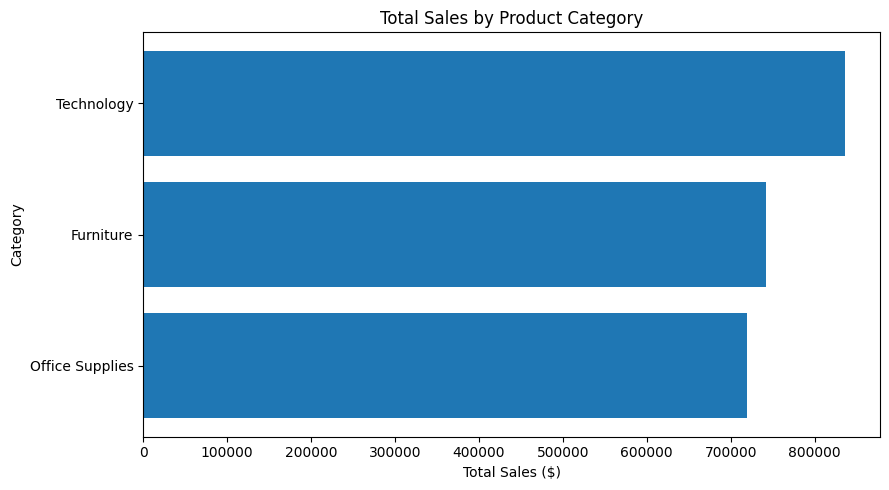

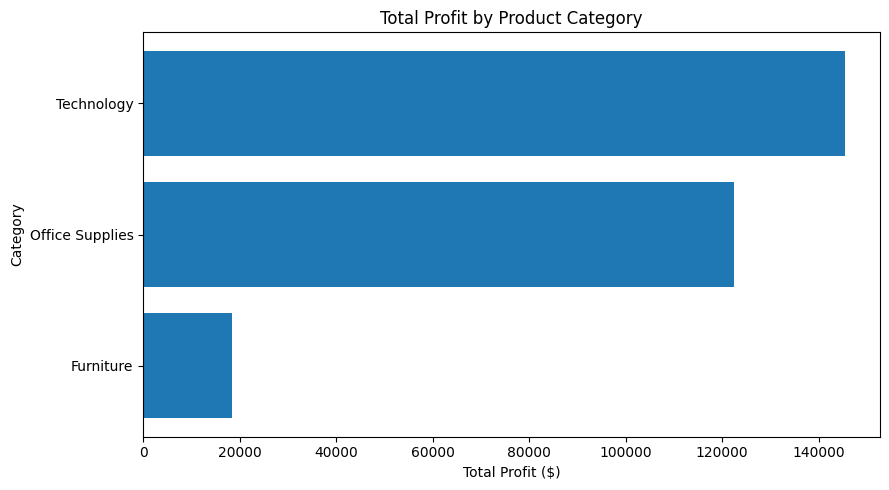

In [25]:

# Chart 1: Total sales by category
category_sales = category_performance.sort_values(
    "Total_Sales", ascending=True
)

plt.figure(figsize=(9, 5))
plt.barh(category_sales.index, category_sales["Total_Sales"])
plt.title("Total Sales by Product Category")
plt.xlabel("Total Sales ($)")
plt.ylabel("Category")
plt.tight_layout()
plt.savefig("charts/sales_by_category.png", dpi=300, bbox_inches="tight")
plt.show()


# Chart 2: Total profit by category
category_profit = category_performance.sort_values(
    "Total_Profit", ascending=True
)

plt.figure(figsize=(9, 5))
plt.barh(category_profit.index, category_profit["Total_Profit"])
plt.title("Total Profit by Product Category")
plt.xlabel("Total Profit ($)")
plt.ylabel("Category")
plt.tight_layout()
plt.savefig("charts/profit_by_category.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:

# Calculate sales and profit by region
region_performance = (
    df.groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Units_Sold=("Quantity", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(region_performance.round(2))


,Total_Sales,Total_Profit,Total_Orders,Units_Sold
Region,,,,
West,725457.82,108418.45,1611,12266
East,678781.24,91522.78,1401,10618
Central,501239.89,39706.36,1175,8780
South,391721.90,46749.43,822,6209


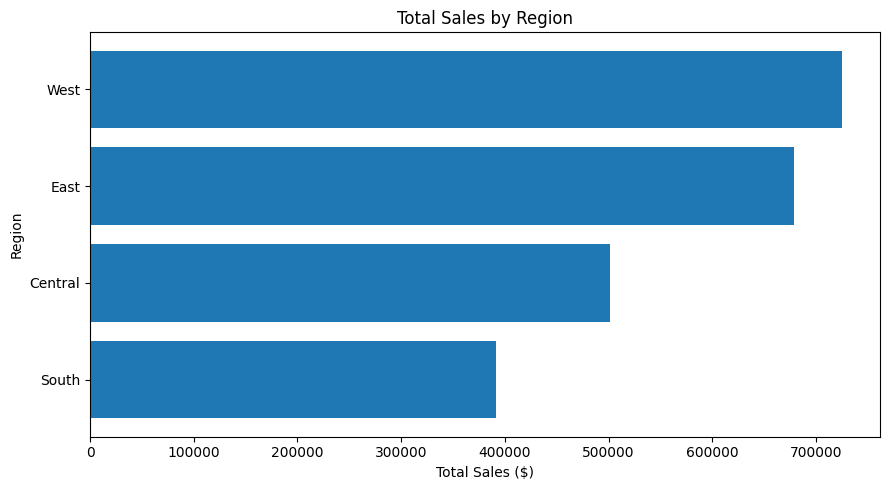

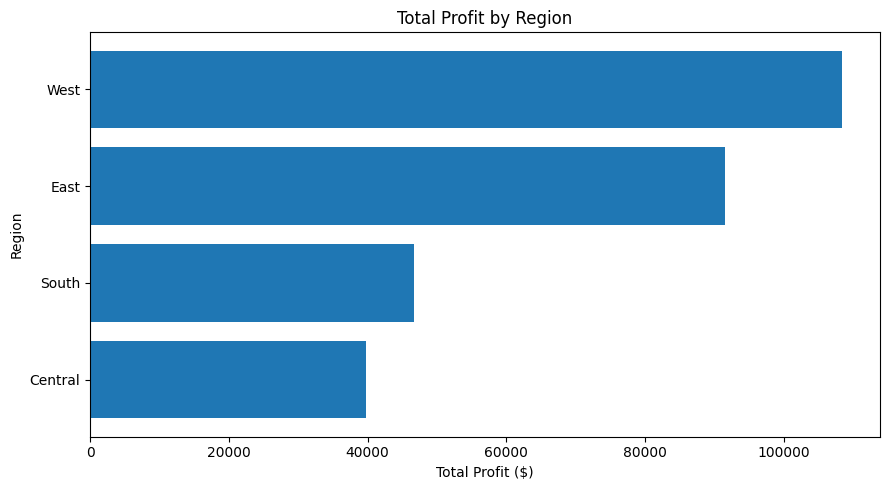

In [27]:

# Regional sales chart
region_sales = region_performance.sort_values("Total_Sales")

plt.figure(figsize=(9, 5))
plt.barh(region_sales.index, region_sales["Total_Sales"])
plt.title("Total Sales by Region")
plt.xlabel("Total Sales ($)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

# Regional profit chart
region_profit = region_performance.sort_values("Total_Profit")

plt.figure(figsize=(9, 5))
plt.barh(region_profit.index, region_profit["Total_Profit"])
plt.title("Total Profit by Region")
plt.xlabel("Total Profit ($)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()


In [14]:
    
# Create a monthly period column
df["Order Month"] = df["Order Date"].dt.to_period("M")

# Calculate monthly performance
monthly_performance = (
    df.groupby("Order Month")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .sort_index()
)

display(monthly_performance.round(2))


,Total_Sales,Total_Profit
Order Month,,
2014-01,14236.90,2450.19
2014-02,4519.89,862.31
2014-03,55691.01,498.73
2014-04,28295.34,3488.84
2014-05,23648.29,2738.71
2014-06,34595.13,4976.52
2014-07,33946.39,-841.48
2014-08,27909.47,5318.10
2014-09,81777.35,8328.10


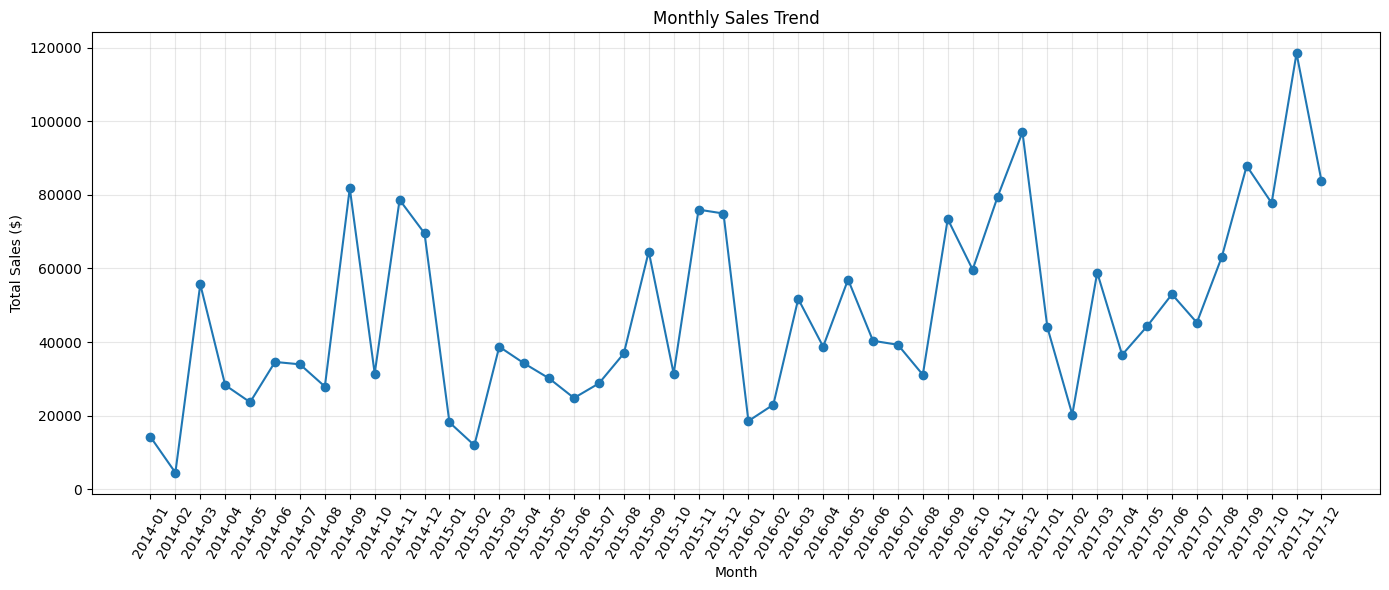

In [28]:

# Monthly sales trend
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_performance.index.astype(str),
    monthly_performance["Total_Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("charts/monthly_sales_trend.png", dpi=300, bbox_inches="tight")
plt.show()


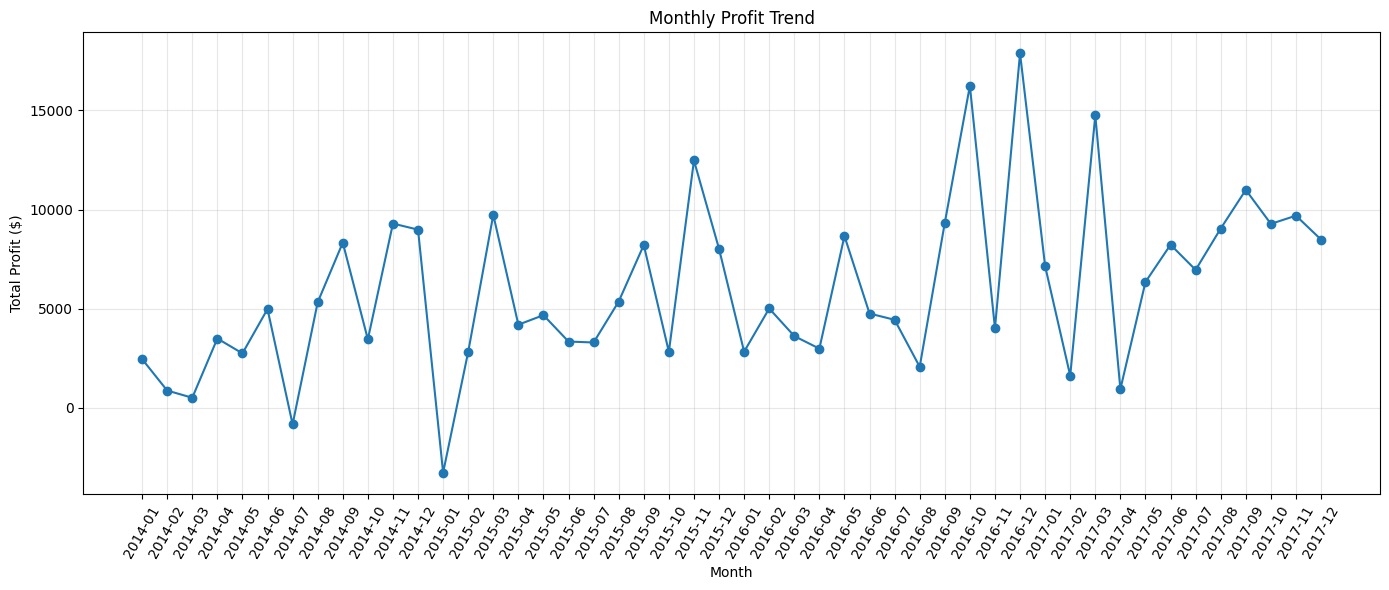

In [29]:
# Monthly Profit Trend

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_performance.index.astype(str),
    monthly_performance["Total_Profit"],
    marker="o"
)

plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Total Profit ($)")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("charts/monthly_profit_trend.png", dpi=300, bbox_inches="tight")
plt.show()

In [17]:

subcategory_performance = (
    df.groupby("Sub-Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Average_Discount=("Discount", "mean"),
        Units_Sold=("Quantity", "sum")
    )
    .sort_values("Total_Profit")
)

display(subcategory_performance.round(2))


,Total_Sales,Total_Profit,Average_Discount,Units_Sold
Sub-Category,,,,
Tables,206965.53,-17725.48,0.26,1241
Bookcases,114880.00,-3472.56,0.21,868
Supplies,46673.54,-1189.10,0.08,647
Fasteners,3024.28,949.52,0.08,914
Machines,189238.63,3384.76,0.31,440
Labels,12486.31,5546.25,0.07,1400
Art,27118.79,6527.79,0.07,3000
Envelopes,16476.40,6964.18,0.08,906
Furnishings,91705.16,13059.14,0.14,3563


In [18]:

discount_analysis = (
    df.groupby("Discount")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Number_of_Rows=("Discount", "size")
    )
    .sort_index()
)

display(discount_analysis.round(2))


,Total_Sales,Total_Profit,Number_of_Rows
Discount,,,
0.00,1087908.47,320987.60,4798
0.10,54369.35,9029.18,94
0.15,27558.52,1418.99,52
0.20,764594.37,90337.31,3657
0.30,103226.66,-10369.28,227
0.32,14493.46,-2391.14,27
0.40,116417.78,-23057.05,206
0.45,5484.97,-2493.11,11
0.50,58918.54,-20506.43,66


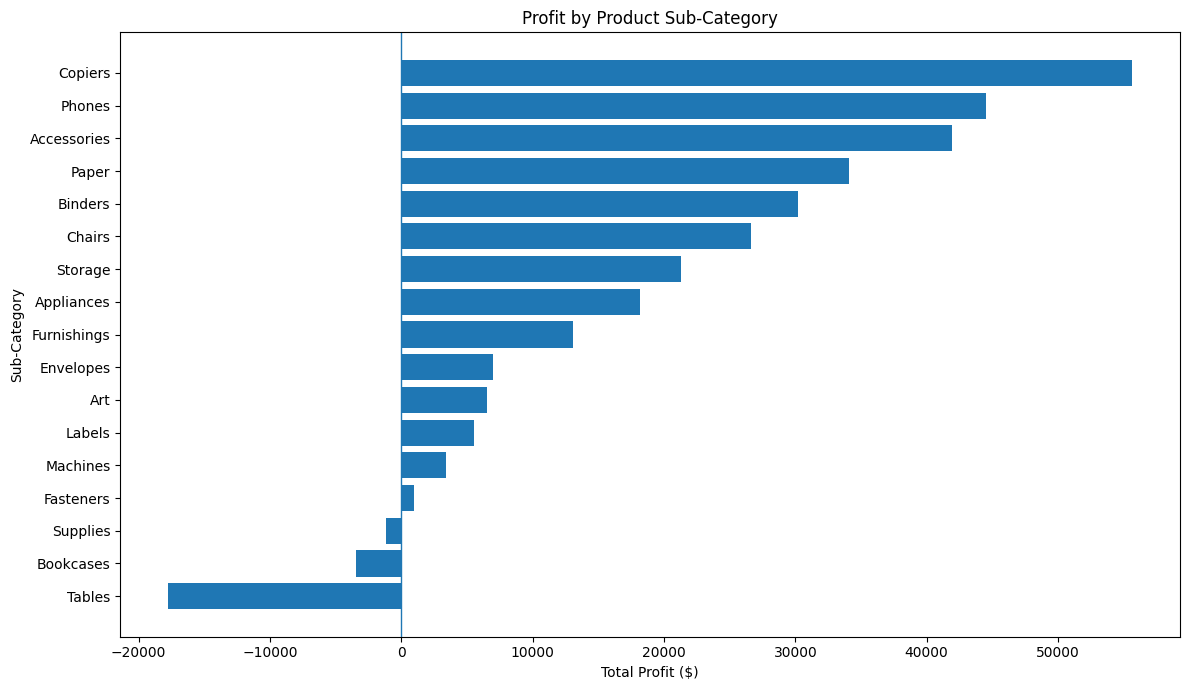

In [30]:
# Profit by Product Sub-Category

subcategory_profit = (
    df.groupby("Sub-Category")["Profit"]
    .sum()
    .sort_values(ascending=True)
)

plt.figure(figsize=(12, 7))
plt.barh(subcategory_profit.index, subcategory_profit.values)
plt.title("Profit by Product Sub-Category")
plt.xlabel("Total Profit ($)")
plt.ylabel("Sub-Category")
plt.axvline(0, linewidth=1)
plt.tight_layout()
plt.savefig("charts/profit_by_subcategory.png", dpi=300, bbox_inches="tight")
plt.show()

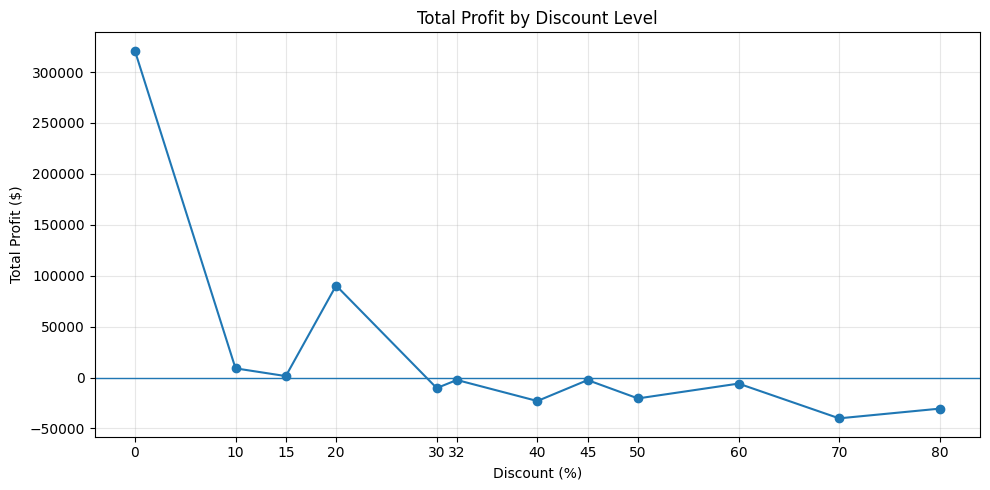

In [31]:
# Total Profit by Discount Level

discount_performance = (
    df.groupby("Discount")["Profit"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(10, 5))
plt.plot(
    discount_performance.index * 100,
    discount_performance.values,
    marker="o"
)

plt.axhline(0, linewidth=1)
plt.title("Total Profit by Discount Level")
plt.xlabel("Discount (%)")
plt.ylabel("Total Profit ($)")
plt.xticks(discount_performance.index * 100)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("charts/profit_by_discount.png", dpi=300, bbox_inches="tight")
plt.show()

In [21]:

# 1. Lowest-profit sub-categories
print("BOTTOM 5 SUB-CATEGORIES BY PROFIT")
display(
    subcategory_performance
    .sort_values("Total_Profit")
    .head(5)
    .round(2)
)

# 2. Highest-profit sub-categories
print("TOP 5 SUB-CATEGORIES BY PROFIT")
display(
    subcategory_performance
    .sort_values("Total_Profit", ascending=False)
    .head(5)
    .round(2)
)

# 3. Overall profit margin by category
category_margin = category_performance.copy()
category_margin["Profit_Margin_%"] = (
    category_margin["Total_Profit"]
    / category_margin["Total_Sales"] * 100
)

print("PROFIT MARGIN BY CATEGORY")
display(category_margin.round(2))

# 4. Check date range
print("Data starts:", df["Order Date"].min().date())
print("Data ends:", df["Order Date"].max().date())


BOTTOM 5 SUB-CATEGORIES BY PROFIT


,Total_Sales,Total_Profit,Average_Discount,Units_Sold
Sub-Category,,,,
Tables,206965.53,-17725.48,0.26,1241
Bookcases,114880.00,-3472.56,0.21,868
Supplies,46673.54,-1189.10,0.08,647
Fasteners,3024.28,949.52,0.08,914
Machines,189238.63,3384.76,0.31,440


TOP 5 SUB-CATEGORIES BY PROFIT


,Total_Sales,Total_Profit,Average_Discount,Units_Sold
Sub-Category,,,,
Copiers,149528.03,55617.82,0.16,234
Phones,330007.05,44515.73,0.15,3289
Accessories,167380.32,41936.64,0.08,2976
Paper,78479.21,34053.57,0.07,5178
Binders,203412.73,30221.76,0.37,5974


PROFIT MARGIN BY CATEGORY


,Total_Sales,Total_Profit,Units_Sold,Profit_Margin_%
Category,,,,
Technology,836154.03,145454.95,6939,17.40
Furniture,741999.80,18451.27,8028,2.49
Office Supplies,719047.03,122490.80,22906,17.04


Data starts: 2014-01-03
Data ends: 2017-12-30


In [23]:
plt.savefig("charts/sales_by_category.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

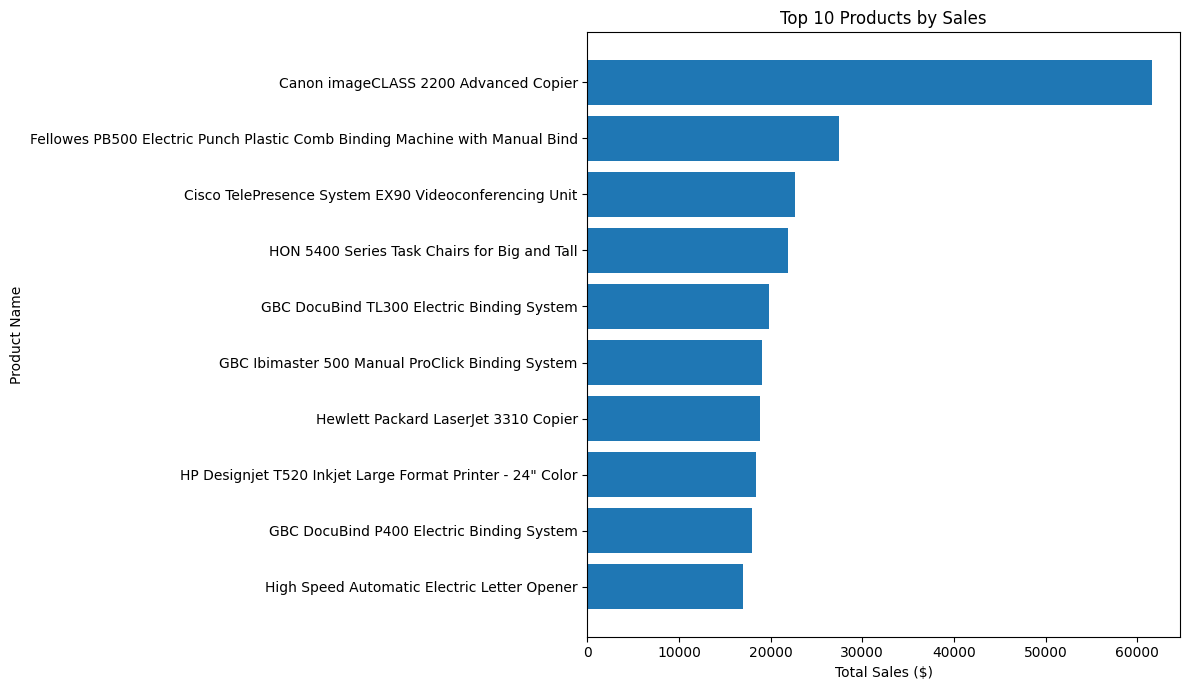

In [32]:
# Top 10 Products by Sales

top_products = (
    df.groupby("Product Name")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Units_Sold=("Quantity", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
    .head(10)
    .sort_values("Total_Sales")
)

plt.figure(figsize=(12, 7))
plt.barh(top_products.index, top_products["Total_Sales"])
plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales ($)")
plt.ylabel("Product Name")
plt.tight_layout()
plt.savefig("charts/top10_products_by_sales.png", dpi=300, bbox_inches="tight")
plt.show()

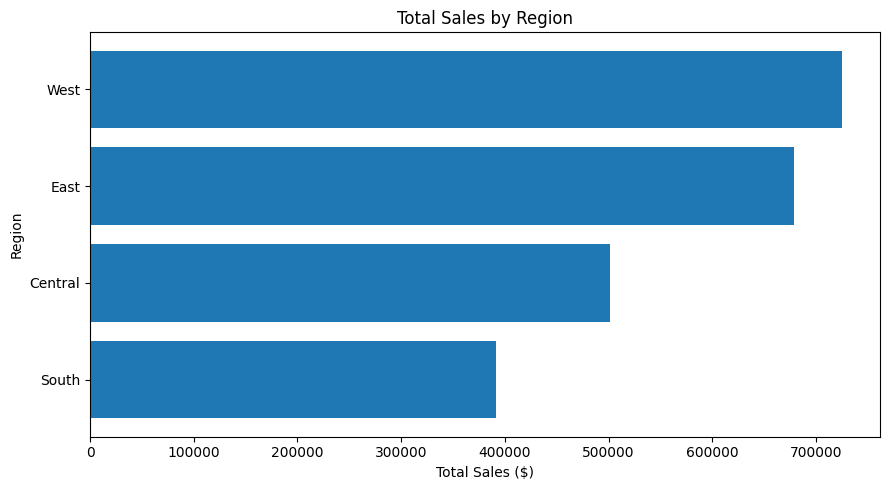

In [33]:

# Sales by Region
region_sales = region_performance.sort_values("Total_Sales")

plt.figure(figsize=(9, 5))
plt.barh(region_sales.index, region_sales["Total_Sales"])
plt.title("Total Sales by Region")
plt.xlabel("Total Sales ($)")
plt.ylabel("Region")
plt.tight_layout()
plt.savefig("charts/sales_by_region.png", dpi=300, bbox_inches="tight")
plt.show()


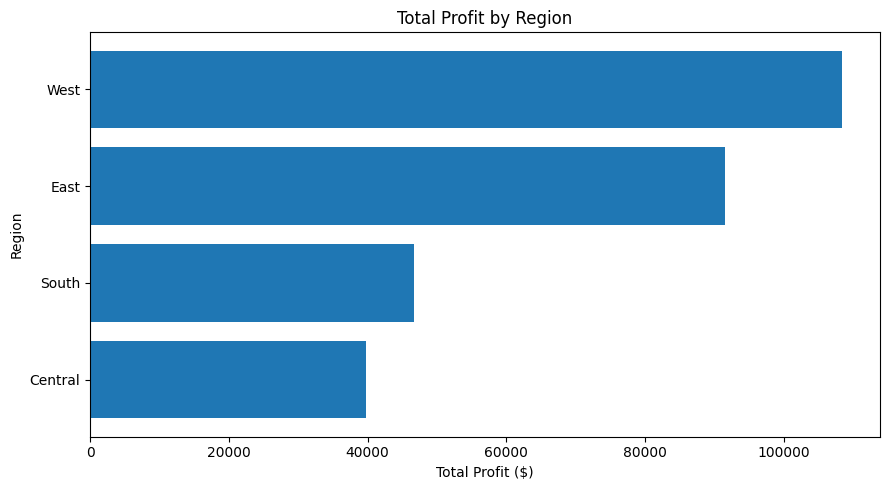

In [34]:

# Profit by Region
region_profit = region_performance.sort_values("Total_Profit")

plt.figure(figsize=(9, 5))
plt.barh(region_profit.index, region_profit["Total_Profit"])
plt.title("Total Profit by Region")
plt.xlabel("Total Profit ($)")
plt.ylabel("Region")
plt.tight_layout()
plt.savefig("charts/profit_by_region.png", dpi=300, bbox_inches="tight")
plt.show()


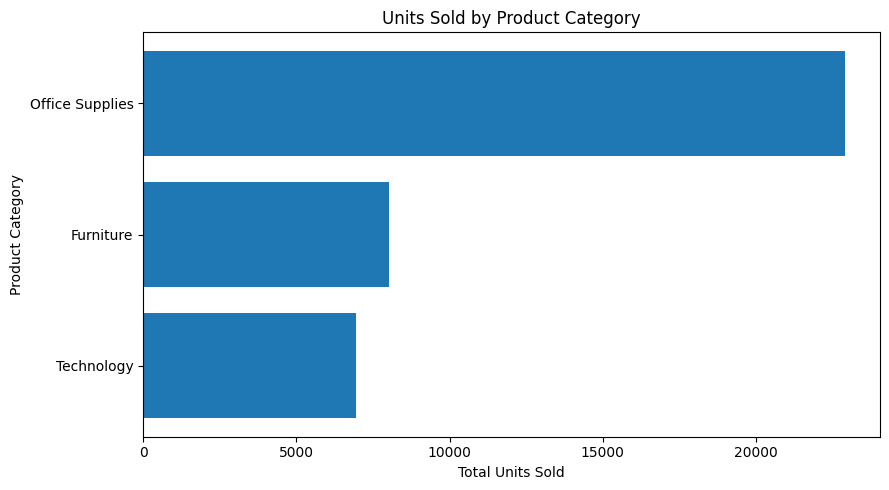

In [35]:

# Units sold by product category
category_units = df.groupby("Category")["Quantity"].sum().sort_values()

plt.figure(figsize=(9, 5))
plt.barh(category_units.index, category_units.values)

plt.title("Units Sold by Product Category")
plt.xlabel("Total Units Sold")
plt.ylabel("Product Category")
plt.tight_layout()

plt.savefig("charts/units_sold_by_category.png", dpi=300, bbox_inches="tight")
plt.show()


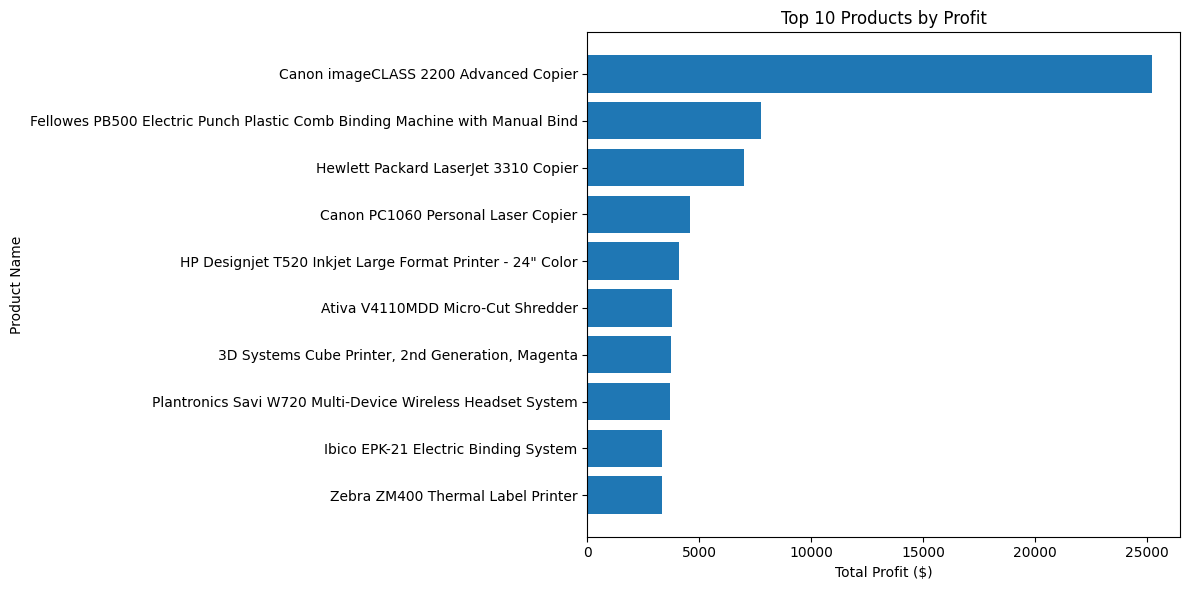

In [36]:

# Top 10 products by profit
product_profit = (
    df.groupby("Product Name")["Profit"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

plt.figure(figsize=(12, 6))
plt.barh(product_profit.index, product_profit.values)

plt.title("Top 10 Products by Profit")
plt.xlabel("Total Profit ($)")
plt.ylabel("Product Name")
plt.tight_layout()

plt.savefig("charts/top10_products_by_profit.png",
            dpi=300, bbox_inches="tight")
plt.show()


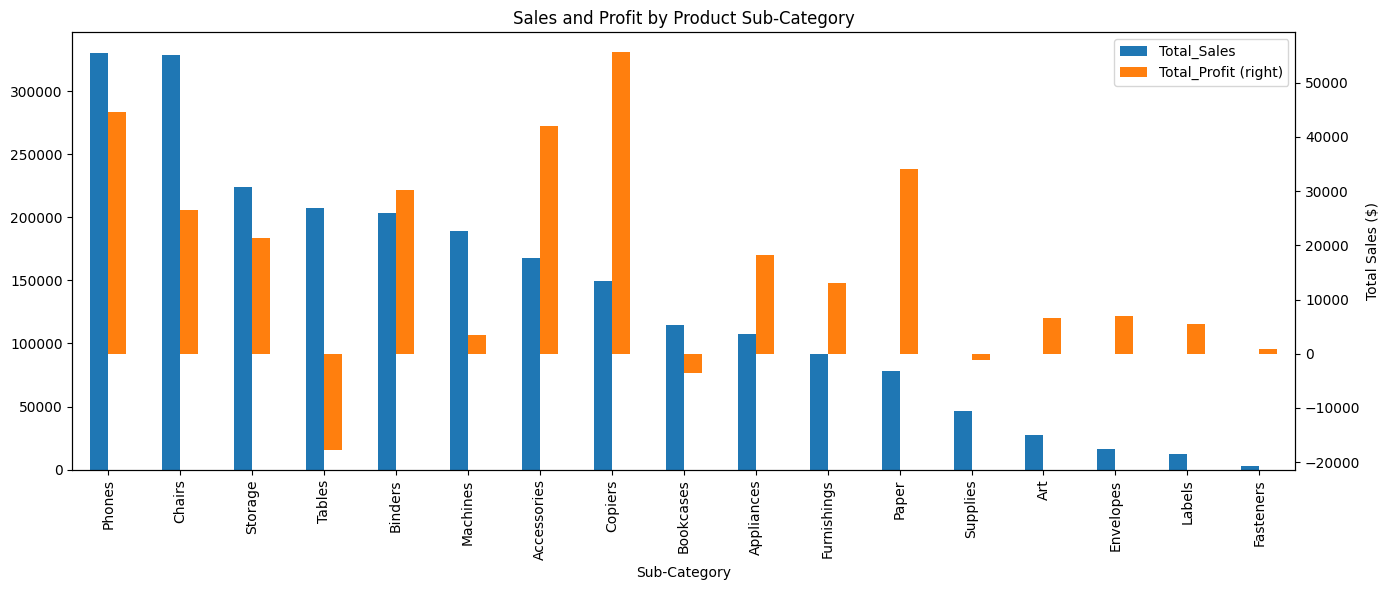

In [37]:

# Compare sales and profit by sub-category
subcategory_comparison = (
    df.groupby("Sub-Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
)

ax = subcategory_comparison.plot(
    kind="bar",
    figsize=(14, 6),
    secondary_y="Total_Profit"
)

plt.title("Sales and Profit by Product Sub-Category")
plt.xlabel("Sub-Category")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    "charts/sales_profit_by_subcategory.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


## Business Insights and Recommendations

### Key Insights

1. **Category performance:** Technology has the highest total sales and profit among the three product categories in this analysis.
2. **Regional performance:** The West region leads in both sales and profit, while the South region has the lowest sales.
3. **Monthly sales trend:** Sales fluctuate throughout the period, with a noticeable peak in November 2017.
4. **Sub-category profitability:** Copiers, Phones, and Accessories are among the strongest sub-categories by total profit.
5. **Loss-making sub-categories:** Tables, Bookcases, and Supplies show negative total profit and require further investigation.
6. **Discount impact:** Several higher discount levels are associated with negative total profit in this dataset. Discounting should be evaluated against the profit generated.

### Business Recommendations

- **Prioritize profitable categories:** Review inventory and marketing opportunities for Technology products while tracking their profit margins.
- **Investigate regional differences:** Study successful sales practices in the West and identify opportunities to improve performance in the South.
- **Plan for seasonal demand:** Review monthly sales patterns to support inventory planning and promotional schedules.
- **Review loss-making products:** Investigate pricing, costs, and discounting for Tables, Bookcases, and Supplies before changing product strategy.
- **Improve discount decisions:** Evaluate discounts based on profit, not sales volume alone, and review high-discount transactions that generate losses.
- **Monitor performance regularly:** Track sales, profit, units sold, and profit margin by category, region, and sub-category.

*These findings are based on the analyzed dataset. Further investigation is recommended before making business decisions.*

## Conclusion

This project analyzed Superstore sales data using Python, Pandas, Matplotlib, and Seaborn. The analysis explored sales and profit by product category, sub-category, region, month, discount level, and product.

The results highlight differences in category and regional performance, seasonal sales patterns, and sub-categories that generate losses. The findings can help businesses improve inventory planning, review discount strategies, identify profitable products, and investigate loss-making areas.

All findings are based on the analyzed dataset and should be validated against additional business information before making final decisions.

## Tools and Technologies

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Jupyter Notebook
- Microsoft Excel

## Project Deliverables

- Data analysis notebook
- Sales and profit visualizations
- Business insights and recommendations
- README documentation